In [3]:
# =========================
# 1) Môi trường (dùng torch có sẵn của Kaggle - KHÔNG cần venv/mmcv)
# =========================
import sys, subprocess

# ── 1a. Đảm bảo `packaging` tồn tại ──
try:
    from packaging import version
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "packaging"], check=True)
    from packaging import version

# ── 1b. Nâng cấp transformers + accelerate nếu cần ──
_MIN_TF = "4.41"
_MIN_ACC = "0.30"
_UPGRADED = False

import transformers
if version.parse(transformers.__version__) < version.parse(_MIN_TF):
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        f"transformers>={_MIN_TF},<5.0",
        f"accelerate>={_MIN_ACC},<1.0",
    ], check=True)
    _UPGRADED = True

# ── 1c. Nếu vừa upgrade → xóa cache module cũ → buộc dừng ──
if _UPGRADED:
    for _mod in list(sys.modules):
        if _mod == "transformers" or _mod.startswith("transformers."):
            del sys.modules[_mod]
    raise SystemExit(
        f"✅ Đã nâng cấp transformers ≥ {_MIN_TF}, accelerate ≥ {_MIN_ACC}\n"
        f"⚠️  RESTART KERNEL rồi chạy lại từ đầu (Kernel → Restart & Run All)."
    )

# ── 1d. Verify lần cuối (an toàn cho trường hợp SystemExit bị nuốt khi Run All) ──
import importlib
transformers = importlib.import_module("transformers")
assert version.parse(transformers.__version__) >= version.parse(_MIN_TF), (
    f"transformers {transformers.__version__} < {_MIN_TF} — Restart kernel rồi chạy lại!"
)

# ── 1e. Import chính + kiểm tra phiên bản ──
import torch, torchvision, cv2

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} "
      f"| transformers {transformers.__version__} | cv2 {cv2.__version__}")

_tv_ver = torchvision.__version__.split("+")[0].split("a")[0].split("b")[0]
assert version.parse(_tv_ver) >= version.parse("0.15"), (
    f"swin3d_b cần torchvision ≥ 0.15, hiện tại: {torchvision.__version__}"
)

# ── 1f. Kiểm tra GPU ──
assert torch.cuda.is_available(), (
    "CUDA không khả dụng — Bật GPU trong Kaggle: Settings → Accelerator → GPU T4 ×2"
)

_total_vram = 0.0
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    _total_vram += p.total_memory / 1024**3
    print(f"  GPU {i}: {p.name} | {p.total_memory / 1024**3:.1f} GB "
          f"| Compute {p.major}.{p.minor} | SM ×{p.multi_processor_count}")

print(f"  Total: {torch.cuda.device_count()} GPU(s) | {_total_vram:.1f} GB VRAM")

del _MIN_TF, _MIN_ACC, _UPGRADED, _tv_ver, _total_vram

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | transformers 5.16.1 | cv2 4.14.0
  GPU 0: Tesla T4 | 14.6 GB | Compute 7.5 | SM ×40
  GPU 1: Tesla T4 | 14.6 GB | Compute 7.5 | SM ×40
  Total: 2 GPU(s) | 29.1 GB VRAM


In [5]:
# =========================
# 2) Config — Video Swin Transformer
# =========================
import os, json, random
import numpy as np
import torch
from pathlib import Path

# ── Video Swin Model Config ──
MODEL_NAME   = "torchvision/swin3d_b"  # Swin-B, Kinetics-400 (init ImageNet-22K)
NUM_FRAMES   = 16                      # 16 frames → patch_temporal=2 → 8 temporal tokens = đúng window_size[0]=8
IMG_SIZE     = 224
TRAIN_SCALE_RANGE = (224, 288)         # Random resize cạnh ngắn rồi random crop 224
EVAL_RESIZE  = 224                     # Resize 224 → center crop 224
DROP_PATH    = 0.3                     # Stochastic depth — truyền vào swin3d_b(stochastic_depth_prob=...)
                                       # Mặc định torchvision swin3d_b = 0.3

# ── Training Hyperparameters (2× T4 16GB) ──
NUM_GPUS         = max(1, torch.cuda.device_count())
TRAIN_BATCH_SIZE = 2
EVAL_BATCH_SIZE  = 4
GRAD_ACCUM_STEPS = 4                   # Effective batch = 2 × 4 × 2 GPU = 16
NUM_EPOCHS       = 30
LEARNING_RATE    = 5e-5
WEIGHT_DECAY     = 0.05
WARMUP_RATIO     = 0.1
LR_SCHEDULER     = "cosine"
LABEL_SMOOTHING  = 0.1
NUM_WORKERS      = min(2, os.cpu_count() or 1)   # không vượt quá số CPU core
SEED             = 42
GRADIENT_CHECKPOINTING = True
FP16             = True
METRIC_FOR_BEST  = "f1_macro"
EARLY_STOP_PATIENCE   = 3
EARLY_STOP_THRESHOLD  = 0.0

# ── Paths ──
INPUT_ROOT = Path("/kaggle/input/datasets/doannh/dataset")
WORK_ROOT  = Path("/kaggle/working/EduViolence_Swin")
SPLIT_CSV  = WORK_ROOT / "split" / "annotations.csv"
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

RUN_DIR    = WORK_ROOT / "runs" / MODEL_NAME.split("/")[-1]
CKPT_DIR   = RUN_DIR / "checkpoints"
RESULT_DIR = RUN_DIR / "results"

# ── Validations ──
assert INPUT_ROOT.exists(), (
    f"INPUT_ROOT không tồn tại: {INPUT_ROOT}\n"
    f"→ Kiểm tra tên dataset trong Kaggle Input hoặc sửa đường dẫn."
)
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9, (
    f"Split ratios phải tổng = 1.0, hiện tại = {TRAIN_RATIO + VAL_RATIO + TEST_RATIO}"
)
assert EVAL_RESIZE >= IMG_SIZE, (
    f"EVAL_RESIZE ({EVAL_RESIZE}) < IMG_SIZE ({IMG_SIZE}) → center crop sẽ thiếu pixel"
)
assert TRAIN_SCALE_RANGE[0] >= IMG_SIZE, (
    f"TRAIN_SCALE_RANGE min ({TRAIN_SCALE_RANGE[0]}) < IMG_SIZE ({IMG_SIZE})"
)

for d in (SPLIT_CSV.parent, CKPT_DIR, RESULT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Reproducibility ──
def seed_everything(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    torch.backends.cudnn.deterministic = True    # reproducibility
    torch.backends.cudnn.benchmark     = False   # Cell 7 sẽ bật lại benchmark=True (ưu tiên tốc độ khi train)

seed_everything(SEED)

# ── Lưu hyperparameters (tuple → list cho JSON-safe roundtrip) ──
def _json_safe(v):
    """Chuyển tuple thành list để json roundtrip nhất quán."""
    return list(v) if isinstance(v, tuple) else v

HPARAMS = {k: _json_safe(v) for k, v in globals().items()
           if k.isupper() and isinstance(v, (int, float, str, bool, tuple, list))}

with open(RUN_DIR / "hparams.json", "w") as f:
    json.dump(HPARAMS, f, indent=2)

print(f"MODEL: {MODEL_NAME} | GPUs: {NUM_GPUS} "
      f"| Effective batch: {TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS * NUM_GPUS} "
      f"| DROP_PATH: {DROP_PATH}")

MODEL: torchvision/swin3d_b | GPUs: 2 | Effective batch: 16 | DROP_PATH: 0.3


In [6]:
# =========================
# 3) Class discovery + split (tạo 1 lần, model sau tái sử dụng)
# =========================
import cv2, pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed

VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".webm", ".mpeg", ".mpg", ".wmv", ".m4v"}
GROUP_MAP = {
    "violence": "Violence",
    "non-violence": "Non-Violence",
    "nonviolence": "Non-Violence",
}

def discover(root: Path) -> pd.DataFrame:
    """Scan root/group/class/videos → DataFrame(path, class_name, group)."""
    rows = []
    for gdir in sorted(p for p in root.iterdir() if p.is_dir()):
        key = gdir.name.lower().replace("_", "-").replace(" ", "-")
        if key not in GROUP_MAP:
            print("⚠️ Bỏ qua thư mục:", gdir.name)
            continue
        for cdir in sorted(p for p in gdir.iterdir() if p.is_dir()):
            for f in sorted(cdir.rglob("*")):
                if (f.is_file()
                        and f.suffix.lower() in VIDEO_EXTS
                        and not f.name.startswith(".")
                        and f.stat().st_size > 0):
                    rows.append(dict(
                        path=str(f.relative_to(root)),
                        class_name=cdir.name,
                        group=GROUP_MAP[key],
                    ))
    assert rows, (
        f"Không tìm thấy video nào trong {root}\n"
        f"→ Cần cấu trúc: root/Violence|Non-Violence/ClassName/video.mp4\n"
        f"→ Tên group hợp lệ (sau normalize): {list(GROUP_MAP.keys())}"
    )
    return pd.DataFrame(rows)


def probe(rel):
    """Kiểm tra video có đọc được không + đếm frame. Thread-safe."""
    cap = cv2.VideoCapture(str(INPUT_ROOT / rel))
    try:
        if not cap.isOpened():
            return False, 0
        ok = cap.read()[0]
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if ok else 0
        return bool(ok), n
    except Exception:
        return False, 0
    finally:
        cap.release()


# ── Load hoặc tạo split ──
if SPLIT_CSV.exists():
    df_ann = pd.read_csv(SPLIT_CSV)
    missing = [p for p in df_ann.path if not (INPUT_ROOT / p).exists()]
    assert not missing, f"{len(missing)} file trong split không tồn tại, vd: {missing[:3]}"
    print("✅ Dùng lại split:", SPLIT_CSV)
else:
    df_ann = discover(INPUT_ROOT)
    dup = df_ann.groupby("class_name").group.nunique()
    assert (dup == 1).all(), f"Tên lớp trùng giữa 2 nhóm: {dup[dup > 1].index.tolist()}"

    # Probe video (có progress)
    total = len(df_ann)
    print(f"🔍 Đang kiểm tra {total} video...")
    with ThreadPoolExecutor(min(8, os.cpu_count() or 4)) as ex:
        futures = {ex.submit(probe, rel): i for i, rel in enumerate(df_ann.path)}
        res = [None] * total
        for done_count, fut in enumerate(as_completed(futures), 1):
            res[futures[fut]] = fut.result()
            if done_count % max(1, total // 5) == 0 or done_count == total:
                print(f"  ... {done_count}/{total} ({done_count*100//total}%)")

    df_ann["readable"], df_ann["num_frames"] = zip(*res)
    bad = df_ann[~df_ann.readable | (df_ann.num_frames < 1)]
    if len(bad):
        print(f"⚠️ Loại {len(bad)} video hỏng:", bad.path.head().tolist())
    df_ann = df_ann.drop(bad.index).drop(columns="readable").reset_index(drop=True)

    assert len(df_ann) >= 10, (
        f"Chỉ còn {len(df_ann)} video hợp lệ sau khi lọc — quá ít để train/val/test."
    )

    # ── Stratified split per class ──
    rng = np.random.default_rng(SEED)
    df_ann["split"] = "train"
    for cls, idx in df_ann.groupby("class_name").groups.items():
        idx = rng.permutation(np.array(idx))
        n = len(idx)
        if n < 3:
            # Quá ít → tất cả vào train, cảnh báo
            print(f"⚠️ Class '{cls}' chỉ có {n} video → tất cả vào train (không có val/test)")
            continue
        n_te = max(1, round(n * TEST_RATIO))
        n_va = max(1, round(n * VAL_RATIO))
        # Guard: đảm bảo train còn ít nhất 1 mẫu
        while n_te + n_va >= n and n_te + n_va > 2:
            if n_va > 1:
                n_va -= 1
            elif n_te > 1:
                n_te -= 1
            else:
                break
        if n_te + n_va >= n:
            print(f"⚠️ Class '{cls}' có {n} video — train chỉ còn {n - n_te - n_va}")
        df_ann.loc[idx[:n_te], "split"] = "test"
        df_ann.loc[idx[n_te:n_te + n_va], "split"] = "val"

    CLASSES_ = sorted(df_ann.class_name.unique())
    df_ann["label_id"] = df_ann.class_name.map({c: i for i, c in enumerate(CLASSES_)})
    df_ann.to_csv(SPLIT_CSV, index=False)
    print("✅ Đã tạo split mới:", SPLIT_CSV)

# ── Verify & build maps ──
CLASSES = sorted(df_ann.class_name.unique())
NUM_CLASSES = len(CLASSES)
assert NUM_CLASSES >= 2, f"Cần ít nhất 2 class, chỉ tìm thấy: {CLASSES}"

label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for c, i in label2id.items()}
assert (df_ann.class_name.map(label2id) == df_ann.label_id).all(), "label_id lệch với CLASSES"

VIOLENCE_CLASSES = sorted(df_ann[df_ann.group == "Violence"].class_name.unique())

# ── Summary ──
split_counts = df_ann.split.value_counts()
print(f"\n📊 {NUM_CLASSES} classes | {len(df_ann)} videos "
      f"| train={split_counts.get('train',0)} val={split_counts.get('val',0)} test={split_counts.get('test',0)}")
print(pd.crosstab(df_ann.class_name, df_ann.split, margins=True)
        .assign(group=lambda x: df_ann.groupby("class_name").group.first()
                                .reindex(x.index).fillna("")))

🔍 Đang kiểm tra 2267 video...
  ... 453/2267 (19%)
  ... 906/2267 (39%)
  ... 1359/2267 (59%)
  ... 1812/2267 (79%)
  ... 2265/2267 (99%)
  ... 2267/2267 (100%)
✅ Đã tạo split mới: /kaggle/working/EduViolence_Swin/split/annotations.csv

📊 16 classes | 2267 videos | train=1587 val=340 test=340
split                                    test  train  val   All         group
class_name                                                                   
Dancing                                    18     84   18   120  Non-Violence
Group fighting_ Mob beating                21     96   21   138      Violence
Hair pulling                               19     89   19   127      Violence
Handshaking                                32    150   32   214  Non-Violence
Kicking                                    20     95   20   135      Violence
Peaceful_gathering                         17     79   17   113  Non-Violence
Playing sports                             26    120   26   172  Non-Violence
Punc

In [7]:
# =========================
# 4) Video Swin Transformer (torchvision swin3d_b) — wrap để dùng với HuggingFace Trainer
# =========================
import torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from transformers import PretrainedConfig
from transformers.modeling_outputs import SequenceClassifierOutput
from torchvision.models.video import swin3d_b, Swin3D_B_Weights

# ── Pretrained weights & normalization (lấy từ weights, không hardcode) ──
WEIGHTS = Swin3D_B_Weights.KINETICS400_IMAGENET22K_V1

_tf = WEIGHTS.transforms()
MEAN = tuple(_tf.mean) if hasattr(_tf, "mean") else (0.485, 0.456, 0.406)
STD  = tuple(_tf.std)  if hasattr(_tf, "std")  else (0.229, 0.224, 0.225)
del _tf
print(f"Normalization: mean={MEAN} | std={STD}")


class Swin3DForVideoClassification(nn.Module):
    """
    Wrap torchvision swin3d_b cho HuggingFace Trainer.
    forward(pixel_values (B,T,C,H,W), labels=None) → SequenceClassifierOutput(.loss, .logits)
    """

    def __init__(self, num_labels, drop_path=0.3, grad_ckpt=True):
        super().__init__()
        self.config = PretrainedConfig(
            num_labels=num_labels,
            id2label=id2label,
            label2id=label2id,
            problem_type="single_label_classification",
            model_type="swin3d_b",
            num_frames=NUM_FRAMES,
            image_size=IMG_SIZE,
        )

        # Build backbone — KHÔNG truyền stochastic_depth_prob (torchvision hardcode bên trong)
        backbone = swin3d_b(weights=WEIGHTS)

        # Rescale StochasticDepth nếu DROP_PATH khác default thực tế
        sd_modules = [m for m in backbone.modules()
                      if m.__class__.__name__ == "StochasticDepth"]
        if sd_modules:
            actual_max = max(m.p for m in sd_modules)
            if abs(drop_path - actual_max) > 1e-6:
                scale = drop_path / actual_max if actual_max > 0 else 1.0
                for m in sd_modules:
                    m.p = m.p * scale
                print(f"  ⚙️ Rescaled StochasticDepth: {actual_max} → {drop_path} "
                      f"({len(sd_modules)} layers)")

        # Replace head: 1024 → num_labels
        backbone.head = nn.Linear(backbone.head.in_features, num_labels)
        nn.init.trunc_normal_(backbone.head.weight, std=0.02)
        nn.init.zeros_(backbone.head.bias)

        self.backbone = backbone
        self.grad_ckpt = grad_ckpt

    def forward(self, pixel_values, labels=None):
        net = self.backbone
        x = pixel_values.permute(0, 2, 1, 3, 4)                # (B,T,C,H,W) → (B,C,T,H,W)
        x = net.pos_drop(net.patch_embed(x))                    # → (B,T',H',W',C)

        use_ckpt = self.grad_ckpt and self.training and torch.is_grad_enabled()
        for layer in net.features:
            if isinstance(layer, nn.Sequential):
                for blk in layer:
                    x = checkpoint(blk, x, use_reentrant=False) if use_ckpt else blk(x)
            else:
                x = layer(x)

        x = net.norm(x).permute(0, 4, 1, 2, 3)                 # → (B,C,T',H',W')
        logits = net.head(torch.flatten(net.avgpool(x), 1))     # → (B, num_labels)

        # Loss: tương thích mọi config LABEL_SMOOTHING (0.0 hoặc > 0)
        loss = F.cross_entropy(logits, labels) if labels is not None else None

        return SequenceClassifierOutput(loss=loss, logits=logits)


def build_model():
    return Swin3DForVideoClassification(
        num_labels=NUM_CLASSES,
        drop_path=DROP_PATH,
        grad_ckpt=GRADIENT_CHECKPOINTING,
    )


# ---------- Kiểm tra kiến trúc ----------
_m = build_model()
_conv = next(mod for mod in _m.backbone.patch_embed.modules() if isinstance(mod, nn.Conv3d))

_win = None
for _mod in _m.backbone.features.modules():
    if hasattr(_mod, "window_size"):
        _ws = _mod.window_size
        if isinstance(_ws, torch.Tensor):
            _win = tuple(_ws.tolist())
        elif isinstance(_ws, (list, tuple)):
            _win = tuple(int(v) for v in _ws)
        if _win is not None:
            break

_depths = [len(l) for l in _m.backbone.features if isinstance(l, nn.Sequential)]
_params = sum(p.numel() for p in _m.parameters()) / 1e6

_sdp = [m.p for m in _m.backbone.modules() if m.__class__.__name__ == "StochasticDepth"]
_max_sdp = max(_sdp) if _sdp else None

print(f"patch_size: {tuple(_conv.kernel_size)} | embed_dim: {_conv.out_channels} | window: {_win} "
      f"| depths: {_depths} | head: {_m.backbone.head.in_features}→{_m.backbone.head.out_features} "
      f"| drop_path: max={_max_sdp} (config={DROP_PATH}) | params: {_params:.1f}M")

assert tuple(_conv.kernel_size) == (2, 4, 4) and _conv.out_channels == 128, "Sai patch embed"
assert _depths == [2, 2, 18, 2], "Sai depths"
assert _m.backbone.head.out_features == NUM_CLASSES, "Sai số lớp head"

if _max_sdp is not None:
    assert abs(_max_sdp - DROP_PATH) < 1e-6, (
        f"Stochastic depth max={_max_sdp} ≠ DROP_PATH={DROP_PATH} — model không nhận config!"
    )

if _win is not None:
    assert NUM_FRAMES // 2 >= _win[0], (
        f"NUM_FRAMES={NUM_FRAMES} quá ít cho temporal window={_win[0]} (cần ≥{2*_win[0]})"
    )
else:
    print("⚠️ Không detect được window_size — bỏ qua temporal check")

del _m, _conv, _win, _depths, _params, _sdp, _max_sdp, _mod

Normalization: mean=(0.485, 0.456, 0.406) | std=(0.229, 0.224, 0.225)
Downloading: "https://download.pytorch.org/models/swin3d_b_22k-7c6ae6fa.pth" to /root/.cache/torch/hub/checkpoints/swin3d_b_22k-7c6ae6fa.pth


100%|██████████| 364M/364M [00:07<00:00, 49.5MB/s] 


  ⚙️ Rescaled StochasticDepth: 0.1 → 0.3 (24 layers)
patch_size: (2, 4, 4) | embed_dim: 128 | window: (8, 7, 7) | depths: [2, 2, 18, 2] | head: 1024→16 | drop_path: max=0.3 (config=0.3) | params: 87.7M


train=1587 | val=340 | test=340 | sampling=uniform
Shape: (16, 3, 224, 224) | load ≈ 0.91s/clip → ≈ 1.82s/step (không tính prefetch)


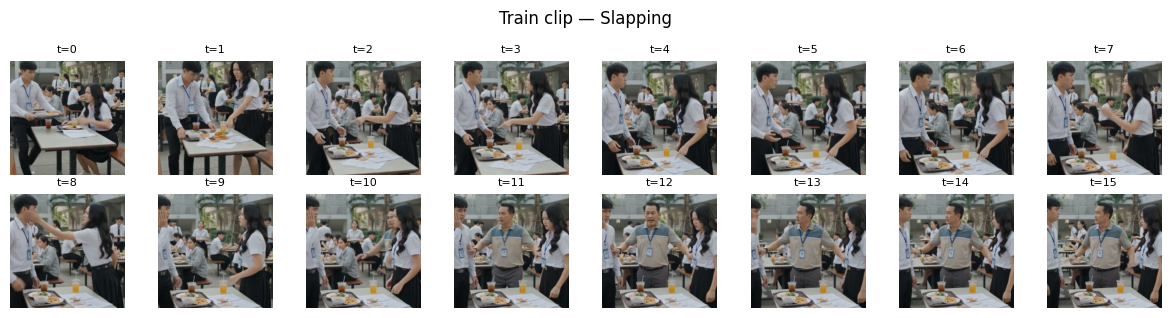

In [8]:
# =========================
# 5) Dataset: sampling uniform (TSN) / dense, đọc video robust
# =========================
import cv2, time, warnings
from collections import defaultdict
from torch.utils.data import Dataset, get_worker_info

cv2.setNumThreads(1)                 # tránh oversubscription với DataLoader workers

SAMPLING = "uniform"                 # "uniform": 16 frame phủ toàn video | "dense": clip liên tục
FRAME_INTERVAL = 4                   # chỉ dùng với "dense": clip dài 16×4 = 64 frame
SEEK_THRESHOLD = 300                 # clip vượt ngưỡng → seek thay vì decode tuần tự
MAX_RETRY = 3
assert min(TRAIN_SCALE_RANGE[0], EVAL_RESIZE) >= IMG_SIZE, "Scale nhỏ hơn IMG_SIZE → crop lỗi"


def _worker_init_fn(worker_id):
    """Seed Python random + numpy per worker để augmentation không trùng lặp."""
    info = get_worker_info()
    seed = info.seed % (2**32)     # torch seed → 32-bit cho random/numpy
    random.seed(seed + worker_id)
    np.random.seed((seed + worker_id) % (2**32))


class VideoClipDataset(Dataset):
    def __init__(self, df, train):
        self.df = df.reset_index(drop=True)
        self.train = train
        self.mean = torch.tensor(MEAN).view(1, 3, 1, 1)
        self.std  = torch.tensor(STD).view(1, 3, 1, 1)
        self.by_class = defaultdict(list)
        for pos, lid in enumerate(self.df.label_id):
            self.by_class[int(lid)].append(pos)
        self.n_true = {}             # cache số frame thực (per worker)

    def __len__(self):
        return len(self.df)

    # ---------- Temporal sampling ----------
    def _uniform(self, n):
        seg = n / NUM_FRAMES
        off = [random.random() if self.train else 0.5 for _ in range(NUM_FRAMES)]
        return [min(int(seg * (k + o)), n - 1) for k, o in enumerate(off)]

    def _indices(self, n):
        n = max(n, 1)
        if SAMPLING == "dense":
            span = (NUM_FRAMES - 1) * FRAME_INTERVAL + 1
            if n >= span:
                start = random.randint(0, n - span) if self.train else (n - span) // 2
                return [start + k * FRAME_INTERVAL for k in range(NUM_FRAMES)]
        return self._uniform(n)

    # ---------- Decoding ----------
    @staticmethod
    def _count(path):
        cap = cv2.VideoCapture(path)
        try:
            n = 0
            while cap.grab():
                n += 1
            return n
        finally:
            cap.release()

    @staticmethod
    def _decode(path, idx):
        """Trả (frames_dict, n_read nếu EOF sớm else None)."""
        cap = cv2.VideoCapture(path)
        if not cap.isOpened():
            raise RuntimeError(f"không mở được video: {path}")
        want, got, stop = set(idx), {}, max(idx)
        try:
            if stop < SEEK_THRESHOLD:                     # đọc tuần tự
                i = 0
                while i <= stop:
                    if not cap.grab():
                        return got, i                     # EOF sớm
                    if i in want:
                        ok, f = cap.retrieve()
                        if ok:
                            got[i] = f
                    i += 1
                return got, None
            for j in sorted(want):                        # seek (video dài)
                cap.set(cv2.CAP_PROP_POS_FRAMES, j)
                ok, f = cap.read()
                if ok:
                    got[j] = f
            return got, None
        finally:
            cap.release()

    def _read(self, path):
        # Đọc & cache frame count (kể cả khi FRAME_COUNT hợp lệ)
        n = self.n_true.get(path)
        if n is None:
            cap = cv2.VideoCapture(path)
            try:
                n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            finally:
                cap.release()
            if n <= 0:
                n = self._count(path)
            self.n_true[path] = n                         # ← LUÔN cache

        for _ in range(2):
            idx = self._indices(n)
            got, n_read = self._decode(path, idx)
            if len(got) == len(set(idx)):
                break
            # FRAME_COUNT khai sai → cập nhật cache + sample lại
            n = n_read if n_read else self._count(path)
            self.n_true[path] = n
        if not got:
            raise RuntimeError("không decode được frame nào")

        keys = np.array(sorted(got))
        rgb = {k: cv2.cvtColor(got[k], cv2.COLOR_BGR2RGB) for k in keys}
        # Frame thiếu → nearest-neighbor temporal fill (giữ đúng NUM_FRAMES)
        return [rgb[keys[np.abs(keys - j).argmin()]] for j in idx]

    # ---------- Spatial ----------
    def _spatial(self, frames):
        s = random.randint(*TRAIN_SCALE_RANGE) if self.train else EVAL_RESIZE
        h, w = frames[0].shape[:2]
        r = s / min(h, w)
        nh, nw = max(IMG_SIZE, round(h * r)), max(IMG_SIZE, round(w * r))
        interp = cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR
        frames = [cv2.resize(f, (nw, nh), interpolation=interp) for f in frames]
        if self.train:
            y = random.randint(0, nh - IMG_SIZE)
            x = random.randint(0, nw - IMG_SIZE)
        else:
            y, x = (nh - IMG_SIZE) // 2, (nw - IMG_SIZE) // 2
        clip = np.stack([f[y:y + IMG_SIZE, x:x + IMG_SIZE] for f in frames])   # (T,H,W,C)
        if self.train and random.random() < 0.5:
            clip = clip[:, :, ::-1]                       # flip ngang (view, ascontiguous ở getitem)
        return clip

    def __getitem__(self, i):
        orig_i = i                                        # lưu index gốc để debug
        for attempt in range(MAX_RETRY):
            r = self.df.iloc[i]
            try:
                clip = self._spatial(self._read(str(INPUT_ROOT / r.path)))
                x = torch.from_numpy(np.ascontiguousarray(clip)).permute(0, 3, 1, 2).float().div_(255)
                x = (x - self.mean) / self.std            # (T, C, H, W)
                return {"pixel_values": x, "labels": torch.tensor(int(r.label_id), dtype=torch.long)}
            except Exception as e:
                if not self.train:
                    raise RuntimeError(f"[eval] lỗi video {r.path}: {e}") from e
                warnings.warn(f"[train] Lỗi {r.path}: {e} → thay bằng mẫu cùng lớp (attempt {attempt+1}/{MAX_RETRY})")
                i = random.choice(self.by_class[int(r.label_id)])
        orig_path = self.df.iloc[orig_i].path
        raise RuntimeError(
            f"{MAX_RETRY} lần liên tiếp đọc lỗi | gốc: {orig_path} | cuối: {r.path} (lớp {r.class_name})"
        )


train_ds = VideoClipDataset(df_ann[df_ann.split == "train"], train=True)
val_ds   = VideoClipDataset(df_ann[df_ann.split == "val"],   train=False)
test_ds  = VideoClipDataset(df_ann[df_ann.split == "test"],  train=False)
print(f"train={len(train_ds)} | val={len(val_ds)} | test={len(test_ds)} | sampling={SAMPLING}")

# ---------- Kiểm tra: tốc độ load + trực quan 1 clip ----------
t0 = time.time()
probe_ids = random.sample(range(len(train_ds)), min(8, len(train_ds)))
samples = [train_ds[k] for k in probe_ids]
dt = (time.time() - t0) / len(samples)
print(f"Shape: {tuple(samples[0]['pixel_values'].shape)} | load ≈ {dt:.2f}s/clip "
      f"→ ≈ {dt * TRAIN_BATCH_SIZE * NUM_GPUS / max(NUM_WORKERS, 1):.2f}s/step (không tính prefetch)")

import matplotlib.pyplot as plt
v = samples[0]["pixel_values"] * train_ds.std + train_ds.mean
ncols = min(NUM_FRAMES, 8)
nrows = (NUM_FRAMES + ncols - 1) // ncols                    # ceil division, hỗ trợ NUM_FRAMES lẻ
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.6))
axes_flat = axes.flat if hasattr(axes, 'flat') else [axes]
for k in range(nrows * ncols):
    ax = axes_flat[k]
    if k < NUM_FRAMES:
        ax.imshow(v[k].permute(1, 2, 0).clamp(0, 1).numpy())
        ax.set_title(f"t={k}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Train clip — {id2label[int(samples[0]['labels'])]}")
plt.tight_layout()
plt.show()

In [6]:
# =========================
# 6) Sanity check: shape, loss ban đầu ≈ ln(C), peak memory
# =========================
import gc, math, time
from torch.utils.data import DataLoader

model = build_model().cuda().train()
n_params    = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

batch = next(iter(DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True)))
x, y = batch["pixel_values"].cuda(), batch["labels"].cuda()
del batch                                                    # giải phóng CPU copy ngay

model.zero_grad(set_to_none=True)                            # clean slate
torch.cuda.reset_peak_memory_stats()
t0 = time.time()

try:
    with torch.autocast("cuda", dtype=torch.float16, enabled=FP16):
        logits = model(pixel_values=x).logits
        loss = F.cross_entropy(logits.float(), y)
    loss.backward()
    torch.cuda.synchronize()
    dt = time.time() - t0
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3

    expected_loss = math.log(NUM_CLASSES)
    print(f"Params: {n_params/1e6:.1f}M (trainable: {n_trainable/1e6:.1f}M)")
    print(f"Input: {tuple(x.shape)} | loss={loss.item():.3f} (kỳ vọng ≈ {expected_loss:.3f})")
    print(f"Peak GPU: {peak_gb:.2f} GB | step: {dt:.2f}s (forward + backward)")

    # Cảnh báo nếu loss khác kỳ vọng quá nhiều (có thể head init bị lệch)
    if abs(loss.item() - expected_loss) > expected_loss * 0.5:
        print(f"⚠️ Loss = {loss.item():.3f} lệch >50% so với kỳ vọng {expected_loss:.3f} — kiểm tra head init")

except torch.cuda.OutOfMemoryError:
    torch.cuda.empty_cache()
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    print(f"❌ CUDA OOM! Peak trước khi crash: {peak_gb:.2f} GB")
    print(f"   → Giảm TRAIN_BATCH_SIZE (hiện tại: {TRAIN_BATCH_SIZE})")
    print(f"   → Hoặc giảm IMG_SIZE (hiện tại: {IMG_SIZE})")
    print(f"   → Hoặc giảm NUM_FRAMES (hiện tại: {NUM_FRAMES})")
    print(f"   → Kiểm tra GRADIENT_CHECKPOINTING=True (hiện tại: {GRADIENT_CHECKPOINTING})")
    raise

finally:
    del model, x, y
    if "loss" in dir():
        del loss
    if "logits" in dir():
        del logits
    gc.collect()
    torch.cuda.empty_cache()

  ⚙️ Rescaled StochasticDepth: 0.1 → 0.3 (24 layers)
Params: 87.7M (trainable: 87.7M)
Input: (2, 16, 3, 224, 224) | loss=3.162 (kỳ vọng ≈ 2.773)
Peak GPU: 2.05 GB | step: 1.70s (forward + backward)


Steps/epoch=100 | total=3000 | warmup=300 | head LR ×1.0 | resume: (train mới)
  ⚙️ Rescaled StochasticDepth: 0.1 → 0.3 (24 layers)
Early stopping: patience=3 | threshold=0.0 | metric=f1_macro
  Optimizer: 4 groups | head params: 0.02M (LR ×1.0) | backbone no-decay params counted separately


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Top5 Acc
1,2.472059,2.237375,0.358824,0.309958,0.758824
2,1.741602,1.490928,0.608824,0.574069,0.944118
3,1.457558,1.287060,0.697059,0.682943,0.964706
4,1.219790,1.236040,0.764706,0.744574,0.958824
5,1.051040,1.171086,0.782353,0.769393,0.976471
6,0.992376,1.124485,0.802941,0.788812,0.976471
7,0.984650,1.087070,0.800000,0.790219,0.973529
8,0.843067,1.050980,0.835294,0.822805,0.979412
9,0.827877,1.015784,0.841176,0.830971,0.979412
10,0.783719,1.020516,0.814706,0.804887,0.985294


✅ Train early stopping | best: /kaggle/working/EduViolence_Swin/runs/swin3d_b/checkpoints/checkpoint-1400 | f1_macro=0.8452


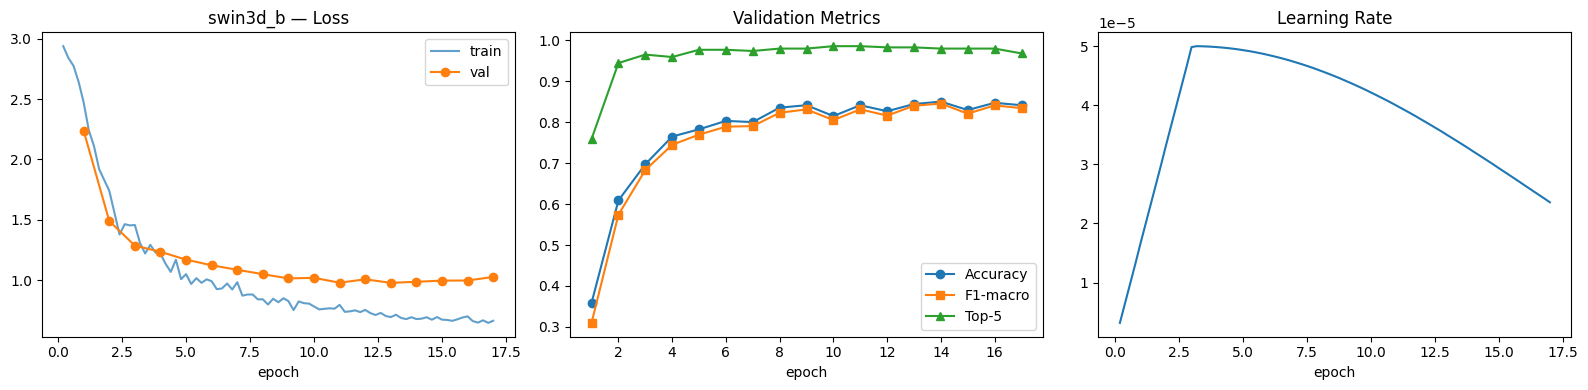

In [7]:
# =========================
# 7) Train Video Swin — HF Trainer (auto-resume, time budget, optimizer chuẩn Swin)
# =========================
import inspect, math, shutil, zipfile, hashlib
import matplotlib.pyplot as plt
from transformers import (
    TrainingArguments, Trainer, TrainerCallback,
    EarlyStoppingCallback, set_seed,
)
from sklearn.metrics import accuracy_score, f1_score
from safetensors import safe_open

MODEL_TAG       = MODEL_NAME.split("/")[-1]
HEAD_LR_MULT    = 1.0       # 1.0 = so sánh công bằng với TimeSformer | 10.0 = recipe gốc Swin
TIME_BUDGET_H   = 10.5      # tự lưu & dừng trước giới hạn 12h Kaggle
FORCE_RESTART   = False
PREV_RUN_DIR    = None       # vd: "/kaggle/input/.../checkpoints"

# Tên attribute head trong model — phải khớp Cell 4
_HEAD_PREFIX = "backbone.head."   # Cell 4 gốc dùng "net.head.", Cell 4 fix dùng "backbone.head."

torch.backends.cudnn.benchmark = True
set_seed(SEED)


# ========== Metrics ==========
def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    y    = p.label_ids
    pred = logits.argmax(-1)
    metrics = {
        "accuracy": accuracy_score(y, pred),
        "f1_macro": f1_score(
            y, pred, average="macro",
            labels=list(range(NUM_CLASSES)), zero_division=0,
        ),
    }
    # Top-5 chỉ có ý nghĩa khi ≥ 5 classes
    if NUM_CLASSES >= 5:
        top5 = np.argsort(logits, axis=1)[:, -5:]
        metrics["top5_acc"] = float(np.mean([t in r for t, r in zip(y, top5)]))
    return metrics


# ========== Checkpoint utils ==========
def ckpt_step(d):
    return int(d.name.split("-")[-1])


def ckpt_valid(d: Path) -> bool:
    """Kiểm tra checkpoint có đủ & không bị cụt."""
    try:
        with open(d / "trainer_state.json", encoding="utf-8") as f:
            json.load(f)
        with zipfile.ZipFile(d / "optimizer.pt") as z:
            if not any(n.endswith("data.pkl") for n in z.namelist()):
                return False
        with safe_open(str(d / "model.safetensors"), "pt") as f:
            if len(list(f.keys())) == 0:
                return False
        return (d / "scheduler.pt").exists()
    except (OSError, json.JSONDecodeError, zipfile.BadZipFile, Exception) as e:
        return False


def latest_valid_ckpt(root: Path):
    for d in sorted(root.glob("checkpoint-*"), key=ckpt_step, reverse=True):
        if ckpt_valid(d):
            return d
        # Chỉ move nếu file corruption, không phải OS error
        try:
            bad = root / "_broken" / d.name
            bad.parent.mkdir(exist_ok=True)
            shutil.move(str(d), str(bad))
            print(f"⚠️ Checkpoint hỏng → chuyển sang {bad}")
        except OSError as e:
            print(f"⚠️ Không thể move checkpoint hỏng {d}: {e}")
    return None


# ========== 1. FORCE_RESTART (lưu trữ, không xoá) ==========
if FORCE_RESTART and any(CKPT_DIR.glob("checkpoint-*")):
    arch = CKPT_DIR.parent / f"checkpoints_archived_{time.strftime('%Y%m%d_%H%M%S')}"
    shutil.move(str(CKPT_DIR), str(arch))
    CKPT_DIR.mkdir(parents=True)
    print(f"📦 Đã lưu trữ checkpoint cũ: {arch} — ĐẶT LẠI FORCE_RESTART=False")

# ========== 2. Khôi phục từ output phiên Kaggle trước ==========
if PREV_RUN_DIR and latest_valid_ckpt(CKPT_DIR) is None:
    src = Path(PREV_RUN_DIR)
    for d in sorted(src.glob("checkpoint-*"), key=ckpt_step):
        if ckpt_valid(d):
            shutil.copytree(d, CKPT_DIR / d.name, dirs_exist_ok=True)
    sig_src = src / "train_hparams.json"
    if sig_src.exists():
        shutil.copy(sig_src, CKPT_DIR / "train_hparams.json")
    print("♻️ Đã copy checkpoint từ", src)

# ========== 3. Guard: config phải khớp khi resume ==========
with open(SPLIT_CSV, "rb") as f:
    split_md5 = hashlib.md5(f.read()).hexdigest()

TRAIN_SIG = {k: HPARAMS.get(k, globals().get(k)) for k in [
    "MODEL_NAME", "NUM_FRAMES", "IMG_SIZE", "TRAIN_BATCH_SIZE", "GRAD_ACCUM_STEPS", "NUM_GPUS",
    "NUM_EPOCHS", "LEARNING_RATE", "WEIGHT_DECAY", "WARMUP_RATIO", "LR_SCHEDULER", "LABEL_SMOOTHING",
    "SEED", "DROP_PATH", "SAMPLING", "FRAME_INTERVAL", "HEAD_LR_MULT",
]}
TRAIN_SIG["split_md5"] = split_md5

sig_file  = CKPT_DIR / "train_hparams.json"
last_ckpt = latest_valid_ckpt(CKPT_DIR)

if last_ckpt and sig_file.exists():
    with open(sig_file, encoding="utf-8") as f:
        old = json.load(f)
    diff = {k: (old.get(k), v) for k, v in TRAIN_SIG.items()
            if str(old.get(k)) != str(v)}
    if diff:
        raise RuntimeError(
            f"Config khác checkpoint đang resume: {diff}\n"
            f"→ Khôi phục config cũ, hoặc đặt FORCE_RESTART=True để train lại."
        )

with open(sig_file, "w", encoding="utf-8") as f:
    json.dump(TRAIN_SIG, f, indent=2)


# ========== 4. SwinTrainer: optimizer + worker_init_fn ==========
class SwinTrainer(Trainer):

    def create_optimizer(self):
        if self.optimizer is None:
            groups = {}
            for name, p in self.model.named_parameters():
                if not p.requires_grad:
                    continue
                no_decay = (
                    p.ndim == 1
                    or name.endswith(".bias")
                    or "relative_position_bias_table" in name
                )
                is_head = name.startswith(_HEAD_PREFIX)
                groups.setdefault((is_head, no_decay), []).append(p)

            self.optimizer = torch.optim.AdamW(
                [
                    {
                        "params": ps,
                        "lr": LEARNING_RATE * (HEAD_LR_MULT if h else 1.0),
                        "weight_decay": 0.0 if nd else WEIGHT_DECAY,
                    }
                    for (h, nd), ps in sorted(groups.items())
                ],
                lr=LEARNING_RATE, betas=(0.9, 0.999), eps=1e-8,
            )
            # Log: verify head params detected
            n_head = sum(p.numel() for (h, _), ps in groups.items() if h for p in ps)
            print(f"  Optimizer: {len(groups)} groups | head params: {n_head/1e6:.2f}M "
                  f"(LR ×{HEAD_LR_MULT}) | backbone no-decay params counted separately")
        return self.optimizer

    def get_train_dataloader(self):
        dl = super().get_train_dataloader()
        dl.worker_init_fn = _worker_init_fn     # seed random + numpy per worker
        return dl

    def get_eval_dataloader(self, eval_dataset=None):
        dl = super().get_eval_dataloader(eval_dataset)
        dl.worker_init_fn = _worker_init_fn
        return dl


# ========== 5. TimeBudget callback ==========
class TimeBudget(TrainerCallback):
    def __init__(self, hours):
        self.deadline = time.time() + hours * 3600
        self.hit = False

    def on_step_end(self, args, state, control, **kw):
        if time.time() > self.deadline:
            self.hit = True
            control.should_save = True
            control.should_training_stop = True
            print(f"\n⏰ Hết time budget tại step {state.global_step} → lưu checkpoint & dừng")
        return control


# ========== 6. TrainingArguments ==========
steps_per_epoch = math.ceil(
    math.ceil(len(train_ds) / (TRAIN_BATCH_SIZE * NUM_GPUS)) / GRAD_ACCUM_STEPS
)
total_steps  = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(round(WARMUP_RATIO * total_steps))

ta_params = inspect.signature(TrainingArguments).parameters
extra = {
    ("eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"): "epoch",
}
if "dataloader_persistent_workers" in ta_params and NUM_WORKERS > 0:
    extra.update(dataloader_persistent_workers=True, dataloader_prefetch_factor=2)

args = TrainingArguments(
    output_dir=str(CKPT_DIR),
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=warmup_steps,
    lr_scheduler_type=LR_SCHEDULER,
    label_smoothing_factor=LABEL_SMOOTHING,
    max_grad_norm=1.0,
    fp16=FP16,
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model=METRIC_FOR_BEST,
    greater_is_better=True,
    logging_steps=max(1, min(20, steps_per_epoch // 3)),
    dataloader_num_workers=NUM_WORKERS,
    dataloader_pin_memory=True,
    remove_unused_columns=False,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    **extra,
)
print(f"Steps/epoch={steps_per_epoch} | total={total_steps} | warmup={warmup_steps} "
      f"| head LR ×{HEAD_LR_MULT} | resume: {last_ckpt or '(train mới)'}")


# ========== 7. Train ==========
free_gb = shutil.disk_usage("/kaggle/working").free / 1024**3
assert free_gb > 3.5, (
    f"Chỉ còn {free_gb:.1f} GB trống — cần ≥3.5 GB cho 2 checkpoint (~1.05 GB/cái) + best"
)

budget = TimeBudget(TIME_BUDGET_H)
early_stopping = EarlyStoppingCallback(
    early_stopping_patience=EARLY_STOP_PATIENCE,
    early_stopping_threshold=EARLY_STOP_THRESHOLD,
)

model   = build_model()
trainer = SwinTrainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    callbacks=[budget, early_stopping],
)
print(f"Early stopping: patience={EARLY_STOP_PATIENCE} | threshold={EARLY_STOP_THRESHOLD} "
      f"| metric={METRIC_FOR_BEST}")

train_out = trainer.train(resume_from_checkpoint=str(last_ckpt) if last_ckpt else None)

# ── Phân biệt 3 trạng thái kết thúc ──
reached_max    = trainer.state.global_step >= trainer.state.max_steps
early_stopped  = (not reached_max) and (not budget.hit)
time_stopped   = budget.hit

if reached_max or early_stopped:
    # Cả hai trường hợp: load_best_model_at_end=True → model hiện tại = best
    trainer.save_model(str(RUN_DIR / "best"))
    reason = "early stopping" if early_stopped else "hoàn thành"
    print(f"✅ Train {reason} | best: {trainer.state.best_model_checkpoint} "
          f"| {METRIC_FOR_BEST}={trainer.state.best_metric:.4f}")
else:
    # Chỉ time budget mới cần resume
    print(f"⏸️ Dừng tại step {trainer.state.global_step}/{trainer.state.max_steps} "
          f"(time budget) — chạy lại cell này hoặc dùng PREV_RUN_DIR để resume")


# ========== 8. Log & curves ==========
hist = pd.DataFrame(trainer.state.log_history)
hist.to_csv(RESULT_DIR / "log_history.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
if "loss" in hist.columns:
    tr = hist.dropna(subset=["loss"])
    if len(tr):
        axes[0].plot(tr.epoch, tr.loss, alpha=0.7, label="train")
if "eval_loss" in hist.columns:
    ev = hist.dropna(subset=["eval_loss"])
    if len(ev):
        axes[0].plot(ev.epoch, ev.eval_loss, "o-", label="val")
axes[0].set_title(f"{MODEL_TAG} — Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

# Metrics
if "eval_accuracy" in hist.columns:
    ev = hist.dropna(subset=["eval_accuracy"])
    if len(ev):
        axes[1].plot(ev.epoch, ev.eval_accuracy,  "o-", label="Accuracy")
        axes[1].plot(ev.epoch, ev.eval_f1_macro,  "s-", label="F1-macro")
        if "eval_top5_acc" in ev.columns:
            axes[1].plot(ev.epoch, ev.eval_top5_acc, "^-", label="Top-5")
        axes[1].legend()
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("epoch")

# Learning rate
if "learning_rate" in hist.columns:
    lr = hist.dropna(subset=["learning_rate"])
    if len(lr):
        axes[2].plot(lr.epoch, lr.learning_rate)
axes[2].set_title("Learning Rate")
axes[2].set_xlabel("epoch")

plt.tight_layout()
plt.savefig(RESULT_DIR / "curves.png", dpi=150)
plt.show()
plt.close(fig)

In [9]:
# =========================
# 8) Load Best Model từ Checkpoint đã train
# =========================
import glob
from pathlib import Path
from safetensors.torch import load_file
import torch.nn as nn

# Tự động dò tìm file model.safetensors trong /kaggle/input hoặc /kaggle/working
ckpt_files = sorted(glob.glob("/kaggle/input/**/best/model.safetensors", recursive=True))
if not ckpt_files:
    ckpt_files = sorted(glob.glob("/kaggle/input/**/model.safetensors", recursive=True))
if not ckpt_files:
    ckpt_files = sorted(glob.glob("/kaggle/working/**/model.safetensors", recursive=True))

assert ckpt_files, "Không tìm thấy file model.safetensors nào trong /kaggle/input!"
best_model_path = Path(ckpt_files[0])
print(f"🎯 Đang nạp weights từ: {best_model_path}")

model = build_model()
state = load_file(str(best_model_path))
model.load_state_dict(state, strict=True)
del state

model = model.cuda().eval()
infer = nn.DataParallel(model) if NUM_GPUS > 1 else model
print("🚀 Model loaded thành công và sẵn sàng Inference!")

🎯 Đang nạp weights từ: /kaggle/input/datasets/doannh/swin-checkpoints/EduViolence_Swin/runs/swin3d_b/best/model.safetensors
  ⚙️ Rescaled StochasticDepth: 0.1 → 0.3 (24 layers)
🚀 Model loaded thành công và sẵn sàng Inference!


In [10]:
# =========================
# 8.5) Inference — Dự đoán tập Test & Lưu predictions.npz
# =========================
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("🚀 Bắt đầu inference trên tập Test...")
test_loader = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH_SIZE * 2,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

all_probs = []
all_labels = []

infer.eval()
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing"):
        x = batch["pixel_values"].cuda()
        y = batch["labels"]
        with torch.autocast("cuda", dtype=torch.float16, enabled=FP16):
            logits = infer(pixel_values=x).logits
            probs = torch.softmax(logits, dim=-1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(y.numpy())

test_probs = np.concatenate(all_probs, axis=0)
test_labels = np.concatenate(all_labels, axis=0)

# Lưu predictions.npz vào RESULT_DIR để Cell 9 & 10 đọc
out_npz = RESULT_DIR / "predictions.npz"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    out_npz,
    test_probs_single=test_probs,
    test_probs=test_probs,
    test_labels=test_labels,
    classes=np.array(CLASSES)
)

print(f"✅ Đã lưu thành công predictions: {out_npz}")
print(f"   Shape: probs={test_probs.shape} | labels={test_labels.shape}")

🚀 Bắt đầu inference trên tập Test...


Testing:   0%|          | 0/43 [00:00<?, ?it/s]

✅ Đã lưu thành công predictions: /kaggle/working/EduViolence_Swin/runs/swin3d_b/results/predictions.npz
   Shape: probs=(340, 16) | labels=(340,)


In [11]:
# =========================
# 9) Classification Report — CHẠY ĐỘC LẬP (không cần chạy cell trước)
# =========================
import re, glob
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report

REPORT_VIEW = "single"          # "single" = canonical center-crop | "final" = multi-view
PRED_FILE   = None              # None = tự tìm | hoặc đường dẫn cụ thể tới predictions.npz
RUN_TAG     = "EduViolence_Swin"   # lọc đúng run, tránh nhặt npz của model khác

DISPLAY_ORDER = [
    "Punching", "Kicking", "Slapping", "Pushing", "Hair pulling",
    "Wrestling down-  Throwing to the ground", "Group fighting_ Mob beating",
    "Threatening with a dangerous weapon",
    "Walking", "Running", "Playing sports", "Handshaking", "Standing still",
    "Sitting", "Peaceful_gathering", "Dancing",
]

# ---------- 1. Tìm predictions.npz ----------
if PRED_FILE is None:
    found = []
    for root in ("/kaggle/working", "/kaggle/input"):
        found += [p for p in sorted(glob.glob(f"{root}/**/results/predictions.npz",
                                              recursive=True)) if RUN_TAG in p]
    assert found, (
        "Không tìm thấy predictions.npz.\n"
        "→ Cell inference (8.5) chưa chạy, hoặc chưa add output notebook cũ vào Input.\n"
        f"→ Nếu file nằm ngoài pattern '*{RUN_TAG}*/results/', gán PRED_FILE thủ công."
    )
    if len(found) > 1:
        print("⚠️ Nhiều file khớp — dùng file đầu tiên:")
        for p in found:
            print("   -", p)
    PRED_FILE = found[0]

PRED_FILE = Path(PRED_FILE)
PRED_DIR  = PRED_FILE.parent          # KHÔNG ghi đè RESULT_DIR của Cell 2
print("→ Dùng:", PRED_FILE)

# ---------- 2. Load + validate ----------
pred = np.load(PRED_FILE, allow_pickle=True)
key  = "test_probs_single" if REPORT_VIEW == "single" else "test_probs"
if key not in pred.files:
    alt = "test_probs" if key == "test_probs_single" else "test_probs_single"
    assert alt in pred.files, f"npz thiếu cả '{key}' và '{alt}' | keys = {pred.files}"
    print(f"⚠️ Không có '{key}' → dùng '{alt}' (REPORT_VIEW không khớp dữ liệu đã lưu)")
    key = alt

probs        = np.asarray(pred[key], dtype=np.float64)
y_true       = np.asarray(pred["test_labels"]).astype(int).ravel()
PRED_CLASSES = [str(c) for c in pred["classes"]]
cls2id       = {c: i for i, c in enumerate(PRED_CLASSES)}

assert probs.ndim == 2, f"probs phải 2-D, nhận {probs.shape}"
assert probs.shape[0] == y_true.size, f"probs {probs.shape[0]} mẫu ≠ labels {y_true.size}"
assert probs.shape[1] == len(PRED_CLASSES), \
    f"probs {probs.shape[1]} cột ≠ {len(PRED_CLASSES)} classes"
assert y_true.min() >= 0 and y_true.max() < len(PRED_CLASSES), \
    f"label_id ngoài phạm vi [0, {len(PRED_CLASSES)-1}]"

y_pred = probs.argmax(1)

# ---------- 3. Nhóm Violence (chỉ dùng để sắp thứ tự hiển thị) ----------
VIOLENCE_CLASSES = []
cands  = [p / "split" / "annotations.csv" for p in PRED_DIR.parents]
cands += [Path(p) for p in glob.glob("/kaggle/working/**/split/annotations.csv", recursive=True)]
csv_path = next((p for p in cands if p.exists()), None)
if csv_path is not None:
    ann = pd.read_csv(csv_path)
    if {"group", "class_name"} <= set(ann.columns):
        VIOLENCE_CLASSES = sorted(ann.loc[ann.group == "Violence", "class_name"].unique())
    print("Split CSV:", csv_path)
else:
    print("ℹ️ Không tìm thấy annotations.csv → bỏ qua nhóm Violence khi sắp thứ tự")

# ---------- 4. Thứ tự hiển thị (khớp tên bỏ qua hoa/thường & khoảng trắng dư) ----------
norm    = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()
by_norm = {norm(c): c for c in PRED_CLASSES}

ordered = []
for n in DISPLAY_ORDER:
    c = by_norm.get(norm(n))
    if c is not None and c not in ordered:
        ordered.append(c)
missing = [n for n in DISPLAY_ORDER if norm(n) not in by_norm]

# Chỉ thêm class CÓ THẬT trong npz → không còn KeyError khi CSV lệch npz
for c in [c for c in VIOLENCE_CLASSES if c in cls2id] + PRED_CLASSES:
    if c not in ordered:
        ordered.append(c)

_in_display = {norm(n) for n in DISPLAY_ORDER}
extra = [c for c in ordered if norm(c) not in _in_display]
if missing: print("⚠️ DISPLAY_ORDER có class không nằm trong npz:", missing)
if extra:   print("ℹ️ Thêm vào cuối (ngoài DISPLAY_ORDER):", extra)

assert len(ordered) == len(PRED_CLASSES), \
    f"ordered {len(ordered)} ≠ classes {len(PRED_CLASSES)} — có class bị trùng/thiếu"
order_ids = [cls2id[c] for c in ordered]

# ---------- 5. In report ----------
kw = dict(labels=order_ids, target_names=ordered, digits=4, zero_division=0)
report_txt = classification_report(y_true, y_pred, **kw)
view = "single-view" if key == "test_probs_single" else "multi-view/final"
print(f"\nVideo Swin Transformer — Test set ({view}) | {len(y_true)} videos "
      f"| top-1 = {(y_pred == y_true).mean():.4f}\n")
print(report_txt)

# ---------- 6. Lưu (luôn ghi vào /kaggle/working vì /kaggle/input read-only) ----------
OUT_DIR = (WORK_ROOT if "WORK_ROOT" in globals()
           else Path("/kaggle/working/EduViolence_Swin")) / "report"
OUT_DIR.mkdir(parents=True, exist_ok=True)

d   = classification_report(y_true, y_pred, output_dict=True, **kw)
acc = d.pop("accuracy", None)                 # tách scalar, tránh broadcast ra 4 cột
report_df = pd.DataFrame(d).T
if acc is not None:
    report_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_true)]

report_df.to_csv(OUT_DIR / f"classification_report_{REPORT_VIEW}.csv")
(OUT_DIR / f"classification_report_{REPORT_VIEW}.txt").write_text(report_txt, encoding="utf-8")
print("Đã lưu:", OUT_DIR)


→ Dùng: /kaggle/working/EduViolence_Swin/runs/swin3d_b/results/predictions.npz
Split CSV: /kaggle/working/EduViolence_Swin/split/annotations.csv

Video Swin Transformer — Test set (single-view) | 340 videos | top-1 = 0.8412

                                         precision    recall  f1-score   support

                               Punching     0.7917    0.8261    0.8085        23
                                Kicking     0.8235    0.7000    0.7568        20
                               Slapping     0.6667    0.7619    0.7111        21
                                Pushing     0.7222    0.7222    0.7222        18
                           Hair pulling     0.6500    0.6842    0.6667        19
Wrestling down-  Throwing to the ground     0.7619    0.7619    0.7619        21
            Group fighting_ Mob beating     0.9500    0.9048    0.9268        21
    Threatening with a dangerous weapon     0.9444    0.8947    0.9189        19
                                Walking     0

In [12]:
# =========================
# 10) Final — Top-1 / Top-5 / F1-macro
# =========================
import glob, json
import numpy as np
from pathlib import Path
from sklearn.metrics import f1_score

RUN_TAG = globals().get("RUN_TAG", "EduViolence_Swin")

# ---------- 1. Tái dùng PRED_FILE của Cell 9, hoặc tự tìm ----------
_pf = globals().get("PRED_FILE")
if _pf is None:
    found = []
    for root in ("/kaggle/working", "/kaggle/input"):
        found += [p for p in sorted(glob.glob(f"{root}/**/results/predictions.npz",
                                              recursive=True)) if RUN_TAG in p]
    assert found, (
        "Không tìm thấy predictions.npz.\n"
        "→ Chạy cell inference (8.5) trước, hoặc gán PRED_FILE thủ công."
    )
    if len(found) > 1:
        print("⚠️ Nhiều file khớp — dùng file đầu tiên:")
        for p in found:
            print("   -", p)
    _pf = found[0]

PRED_FILE = Path(_pf)
pred = np.load(PRED_FILE, allow_pickle=True)
print("→ Dùng:", PRED_FILE)

# ---------- 2. Số class & K thực tế ----------
if "classes" in pred.files:
    CLS = [str(c) for c in pred["classes"]]
    C = len(CLS)
else:
    first = next(k for k in pred.files if k.endswith("probs") or k.endswith("probs_single"))
    C = int(np.asarray(pred[first]).shape[1])
    CLS = [str(i) for i in range(C)]

K = min(5, C)
if K >= C:
    print(f"⚠️ Chỉ có {C} class → Top-{K} luôn = 1.0000, không mang thông tin")

# ---------- 3. Metric ----------
def metrics(probs, labels, k):
    probs  = np.asarray(probs, dtype=np.float64)
    labels = np.asarray(labels).astype(int).ravel()

    assert probs.ndim == 2, f"probs phải 2-D, nhận {probs.shape}"
    assert probs.shape[0] == labels.size, \
        f"probs {probs.shape[0]} mẫu ≠ labels {labels.size} mẫu — file npz không đồng bộ"
    assert probs.shape[1] == C, f"probs {probs.shape[1]} cột ≠ {C} class"
    assert labels.size > 0, "không có mẫu nào"
    assert labels.min() >= 0 and labels.max() < C, f"label_id ngoài [0, {C-1}]"

    y1 = probs.argmax(1)
    top1 = float((y1 == labels).mean())
    if k >= C:
        topk = 1.0
    else:
        idx  = np.argpartition(-probs, k - 1, axis=1)[:, :k]   # nhanh hơn argsort
        topk = float((idx == labels[:, None]).any(1).mean())
    f1 = float(f1_score(labels, y1, average="macro",
                        labels=list(range(C)), zero_division=0))
    return top1, topk, f1, labels.size

ROWS = [
    ("Test  (single-view)", "test_probs_single", "test_labels"),
    ("Test  (multi-view)",  "test_probs",        "test_labels"),
    ("Val   (single-view)", "val_probs_single",  "val_labels"),
]

# ---------- 4. In bảng ----------
W = 64
print("\n" + "=" * W)
print(f"VIDEO SWIN TRANSFORMER — FINAL  ({C} classes, Top-{K})")
print("=" * W)
print(f"{'View':<22}{'N':>5}{'Top-1':>11}{f'Top-{K}':>11}{'F1-macro':>12}")
print("-" * W)

res = {}
for name, pk, lk in ROWS:
    if pk not in pred.files or lk not in pred.files:
        continue
    t1, tk, f1, n = metrics(pred[pk], pred[lk], K)
    res[pk] = dict(top1=t1, topk=tk, f1_macro=f1, n=n, k=K)
    print(f"{name:<22}{n:>5}{t1:>10.4f} {tk:>10.4f} {f1:>11.4f}")

print("=" * W)

# ---------- 5. So sánh single vs multi-view ----------
if "test_probs_single" in res and "test_probs" in res:
    same = np.allclose(np.asarray(pred["test_probs_single"], dtype=np.float64),
                       np.asarray(pred["test_probs"], dtype=np.float64))
    if same:
        print("ℹ️ multi-view ≡ single-view (inference chạy với N_CLIPS=N_CROPS=1)")
    else:
        d1 = res["test_probs"]["top1"]     - res["test_probs_single"]["top1"]
        df = res["test_probs"]["f1_macro"] - res["test_probs_single"]["f1_macro"]
        print(f"Multi-view vs single-view:  Top-1 {d1:+.4f}  |  F1-macro {df:+.4f}")

if "test_probs_single" in res and "val_probs_single" in res:
    gap = res["val_probs_single"]["top1"] - res["test_probs_single"]["top1"]
    print(f"Val − Test (single-view):   Top-1 {gap:+.4f}")

assert res, f"npz không có cặp probs/labels nào dùng được | keys = {pred.files}"

# ---------- 6. Lưu (luôn vào /kaggle/working) ----------
OUT_DIR = (globals().get("WORK_ROOT") or Path("/kaggle/working/EduViolence_Swin")) / "report"
OUT_DIR = Path(OUT_DIR); OUT_DIR.mkdir(parents=True, exist_ok=True)
with open(OUT_DIR / "final_metrics.json", "w", encoding="utf-8") as f:
    json.dump({"pred_file": str(PRED_FILE), "num_classes": C, "topk": K,
               "results": res}, f, indent=2)
print("Đã lưu:", OUT_DIR / "final_metrics.json")

→ Dùng: /kaggle/working/EduViolence_Swin/runs/swin3d_b/results/predictions.npz

VIDEO SWIN TRANSFORMER — FINAL  (16 classes, Top-5)
View                      N      Top-1      Top-5    F1-macro
----------------------------------------------------------------
Test  (single-view)     340    0.8412     0.9735      0.8351
Test  (multi-view)      340    0.8412     0.9735      0.8351
ℹ️ multi-view ≡ single-view (inference chạy với N_CLIPS=N_CROPS=1)
Đã lưu: /kaggle/working/EduViolence_Swin/report/final_metrics.json
